In [15]:
import pandas as pd 
from sklearn.cluster import KMeans

from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

In [2]:
data = [
    [8, 1, 22, 0, 5],
    [10, 1, 25, 1, 8],
    [7, 2, 20, 0, 6],
    [12, 1, 28, 1, 10],
    [9, 2, 24, 0, 7],
    [40, 4, 160, 2, 18],
    [45, 5, 175, 3, 22],
    [38, 3, 150, 1, 15],
    [50, 6, 190, 4, 25],
    [42, 4, 165, 2, 20],
    [18, 8, 45, 12, 65],
    [20, 9, 50, 15, 70],
    [16, 7, 40, 10, 60],
    [22, 10, 55, 18, 75],
    [19, 8, 48, 14, 68],
    [65, 12, 420, 2, 35],
    [70, 14, 460, 3, 40],
    [62, 11, 400, 1, 32],
    [75, 15, 500, 4, 45],
    [68, 13, 450, 2, 38]
]


In [3]:
features = [
    "Outbound Connections",
    "Destination Countries",
    "Bytes per Connection",
    "Failed Logins",
    "After-Hours Activity"
]


In [4]:
df = pd.DataFrame(data, columns=features)
df.insert(0, "Device", [f"D{i}" for i in range(1, 21)])

In [29]:
#Model for Kmeans clustering
model = KMeans(
    n_clusters = 4, 
    init = 'k-means++',
    random_state = 50,
    n_init = 1
)

df["Cluster"] = model.fit_predict(df[features])


In [30]:
## Results display for confirmation
print("Iterations:", model.n_iter_)
print("\nCluster Members:")
print(df.groupby("Cluster")["Device"].apply(list))

print("\nCluster Sizes:")
print(df["Cluster"].value_counts().sort_index())

print("\nFinal Centroids:")
centroids = pd.DataFrame(
    model.cluster_centers_, 
    columns=features
)

print(centroids.round(2))

Iterations: 2

Cluster Members:
Cluster
0        [D6, D7, D8, D9, D10]
1    [D16, D17, D18, D19, D20]
2         [D1, D2, D3, D4, D5]
3    [D11, D12, D13, D14, D15]
Name: Device, dtype: object

Cluster Sizes:
Cluster
0    5
1    5
2    5
3    5
Name: count, dtype: int64

Final Centroids:
   Outbound Connections  Destination Countries  Bytes per Connection  \
0                  43.0                    4.4                 168.0   
1                  68.0                   13.0                 446.0   
2                   9.2                    1.4                  23.8   
3                  19.0                    8.4                  47.6   

   Failed Logins  After-Hours Activity  
0            2.4                  20.0  
1            2.4                  38.0  
2            0.4                   7.2  
3           13.8                  67.6  


In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

In [11]:
scaled_model = KMeans(
    n_clusters = 4,
    init = 'k-means++',
    random_state = 42,
    n_init = 10
)

df["Scaled Cluster"] = scaled_model.fit_predict(X_scaled)

In [12]:
print("Iterations:", scaled_model.n_iter_)

print("\nStandardized Cluster Members:")
print(df.groupby("Scaled Cluster")["Device"].apply(list))

print("\nStandardized Cluster Sizes:")
print(df["Scaled Cluster"].value_counts().sort_index())

print("\nStandardized Final Centroids:")
centroids_scaled = pd.DataFrame(
    scaled_model.cluster_centers_, 
    columns=features
)

print(centroids_scaled.round(2))

Iterations: 4

Standardized Cluster Members:
Scaled Cluster
0         [D1, D2, D3, D4, D5]
1    [D16, D17, D18, D19, D20]
2        [D6, D7, D8, D9, D10]
3    [D11, D12, D13, D14, D15]
Name: Device, dtype: object

Standardized Cluster Sizes:
Scaled Cluster
0    5
1    5
2    5
3    5
Name: count, dtype: int64

Standardized Final Centroids:
   Outbound Connections  Destination Countries  Bytes per Connection  \
0                 -1.11                  -1.21                 -0.87   
1                  1.44                   1.38                  1.63   
2                  0.36                  -0.54                 -0.02   
3                 -0.69                   0.36                 -0.73   

   Failed Logins  After-Hours Activity  
0          -0.79                 -1.13  
1          -0.43                  0.21  
2          -0.43                 -0.57  
3           1.64                  1.50  


In [14]:
results = []
for k in [2, 3, 4, 5, 6]:
    model = KMeans(
        n_clusters = k,
        init = 'k-means++',
        random_state = 42,
        n_init = 10
    )


    labels = model.fit_predict(X_scaled)

    results.append({
        "K": k, 
        "WCSS": round(model.inertia_, 2),
        "Cluster Sizes": sorted(
            pd.Series(labels).value_counts().tolist()
        )
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 K  WCSS      Cluster Sizes
 2 54.19            [5, 15]
 3 13.33         [5, 5, 10]
 4  3.89       [5, 5, 5, 5]
 5  2.71    [2, 3, 5, 5, 5]
 6  1.81 [2, 2, 3, 3, 5, 5]


## Elbow Curve Plot

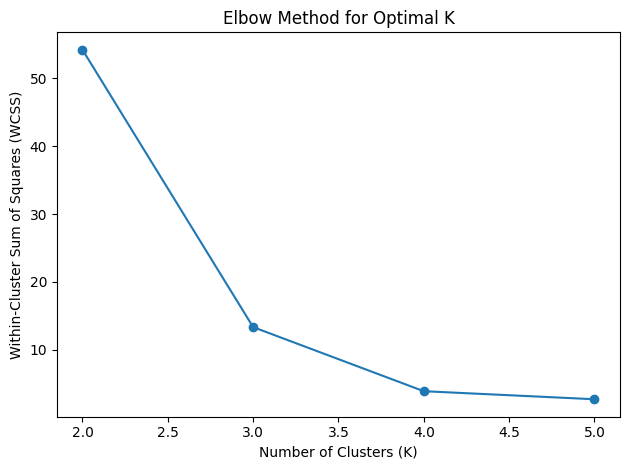

In [20]:
k_values = [2, 3, 4, 5]
wcss = []

for k in k_values:
    model = KMeans(
        n_clusters = k,
        init = 'k-means++',
        random_state = 42,
        n_init = 10
    )

    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(k_values, wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.title('Elbow Method for Optimal K')
plt.tight_layout()

plt.show()

In [31]:
seeds = [10, 20, 30, 40, 50]
stability_results = pd.DataFrame({"Device": df["Device"]})
run_summaries = []

for seed in seeds:
    model = KMeans(
        n_clusters=4,
        init="k-means++",
        random_state=seed,
        n_init=1
    )

    labels = model.fit_predict(X_scaled)
    stability_results[f"Seed {seed}"] = labels

    groups = [
        sorted(df.loc[labels == c, "Device"].tolist(),
               key=lambda d: int(d[1:]))
        for c in range(4)
    ]

    run_summaries.append({
        "Seed": seed,
        "WCSS": round(model.inertia_, 3),
        "Cluster Sizes": sorted(
            pd.Series(labels).value_counts().tolist()
        ),
        "Groups": groups
    })

print("Device Assignments:")
print(stability_results.to_string(index=False))

print("\nRun Summaries:")
for result in run_summaries:
    print(result)


Device Assignments:
Device  Seed 10  Seed 20  Seed 30  Seed 40  Seed 50
    D1        1        2        3        1        3
    D2        1        2        3        1        3
    D3        1        2        3        1        3
    D4        1        2        3        1        3
    D5        1        2        3        1        3
    D6        3        3        1        0        0
    D7        3        3        1        0        0
    D8        3        3        1        0        0
    D9        3        3        1        0        0
   D10        3        3        1        0        0
   D11        2        0        0        2        1
   D12        2        0        0        2        1
   D13        2        0        0        2        1
   D14        2        0        0        2        1
   D15        2        0        0        2        1
   D16        0        1        2        3        2
   D17        0        1        2        3        2
   D18        0        1        2        3  